In [8]:
import pandas as pd
import numpy as np

In [4]:
import seaborn as sns

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Display the first 5 rows
print(df.head())


               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

In [3]:
# Handling missing value
print(df.isnull().sum())


pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [6]:
# Fill missing numerical values with median
for column in df.select_dtypes(include="number").columns:
    df[column] = df[column].fillna(df[column].median())

# Fill missing categorical values with mode
for column in df.select_dtypes(include=["object","string"]).columns:
    df[column] = df[column].fillna(df[column].mode()[0])

# Check missing values again
print(df.isnull().sum())


pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


**Line Chart**


In [9]:
# Convert pickup column into datetime format
df["pickup"] = pd.to_datetime(df["pickup"])

print(df["pickup"].head())



0   2019-03-23 20:21:09
1   2019-03-04 16:11:55
2   2019-03-27 17:53:01
3   2019-03-10 01:23:59
4   2019-03-30 13:27:42
Name: pickup, dtype: datetime64[us]


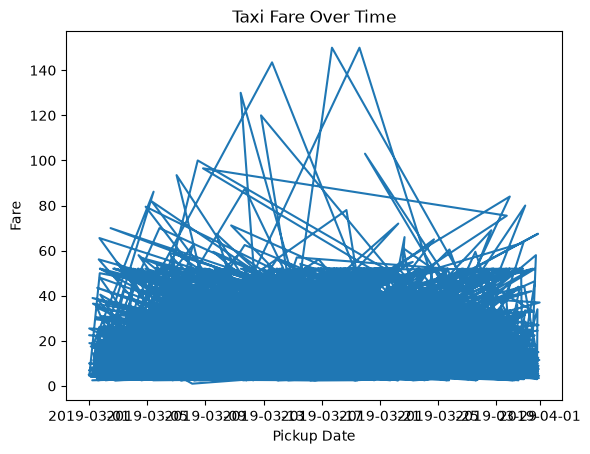

In [10]:
import matplotlib.pyplot as plt

plt.plot(df["pickup"], df["fare"])

plt.xlabel("Pickup Date")
plt.ylabel("Fare")
plt.title("Taxi Fare Over Time")

plt.show()


**Bar Chart**

In [11]:
# Calculate total fare for each pickup borough
borough_fare = df.groupby("pickup_borough")["fare"].sum()

print(borough_fare)


pickup_borough
Bronx         2078.91
Brooklyn      6327.48
Manhattan    59426.42
Queens       16382.06
Name: fare, dtype: float64


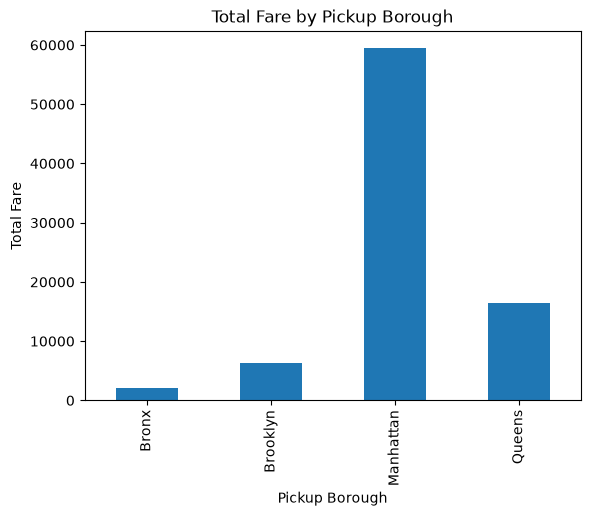

In [12]:
import matplotlib.pyplot as plt

borough_fare.plot(kind="bar")

plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.title("Total Fare by Pickup Borough")

plt.show()


**Pie Chart**

In [13]:
# Count trips by payment method
payment_count = df["payment"].value_counts()

print(payment_count)


payment
credit card    4621
cash           1812
Name: count, dtype: int64


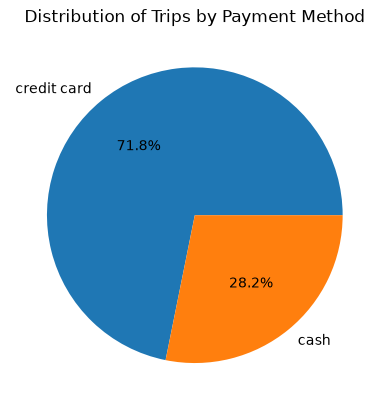

In [14]:
import matplotlib.pyplot as plt

plt.pie(payment_count, labels=payment_count.index, autopct="%1.1f%%")

plt.title("Distribution of Trips by Payment Method")

plt.show()


**Histogarm**

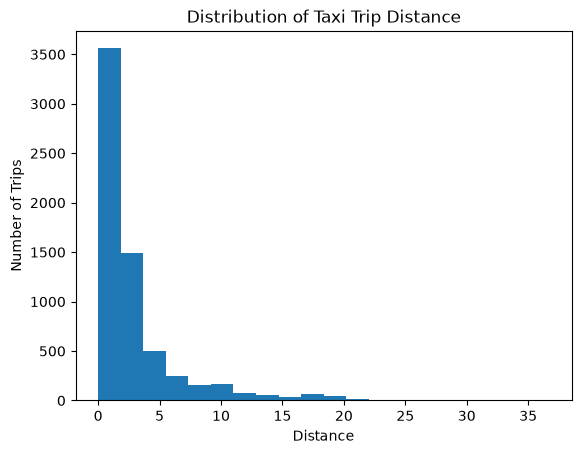

In [15]:
import matplotlib.pyplot as plt

plt.hist(df["distance"], bins=20)

plt.xlabel("Distance")
plt.ylabel("Number of Trips")
plt.title("Distribution of Taxi Trip Distance")

plt.show()


**Box Plot**

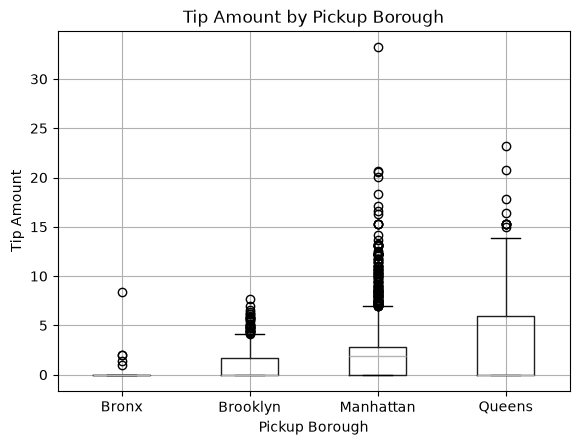

In [16]:
import matplotlib.pyplot as plt

df.boxplot(column="tip", by="pickup_borough")

plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")
plt.title("Tip Amount by Pickup Borough")

plt.suptitle("")

plt.show()


**Count Plot**

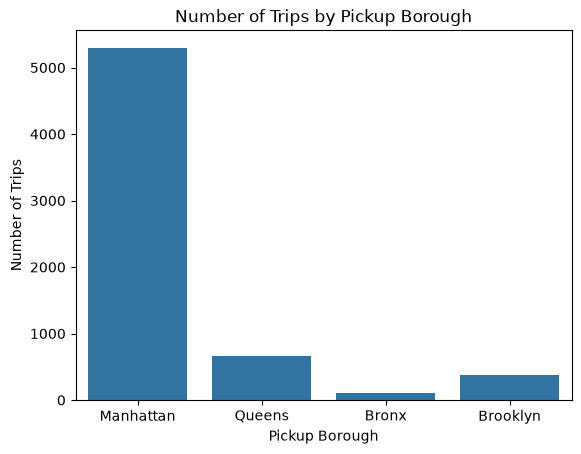

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x="pickup_borough")

plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.title("Number of Trips by Pickup Borough")

plt.show()


**Scatter Plot**

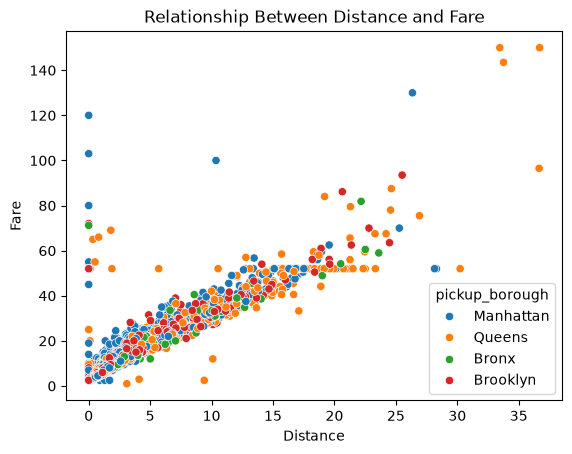

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(data=df, x="distance", y="fare", hue="pickup_borough")

plt.xlabel("Distance")
plt.ylabel("Fare")
plt.title("Relationship Between Distance and Fare")

plt.show()


**Heatmap**

In [20]:
# Select numerical columns
data = df[["distance", "fare", "tip", "tolls", "total"]]


In [21]:
# Calculate correlation
correlation = data.corr()

print(correlation)


          distance      fare       tip     tolls     total
distance  1.000000  0.920108  0.452589  0.635267  0.904676
fare      0.920108  1.000000  0.488612  0.609307  0.974358
tip       0.452589  0.488612  1.000000  0.413619  0.646186
tolls     0.635267  0.609307  0.413619  1.000000  0.683142
total     0.904676  0.974358  0.646186  0.683142  1.000000


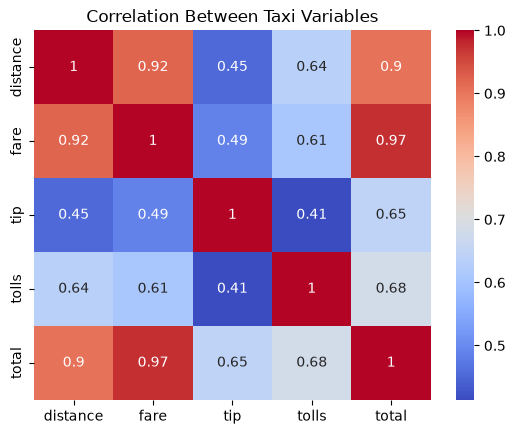

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(correlation, annot=True, cmap="coolwarm")

plt.title("Correlation Between Taxi Variables")

plt.show()


**Pair Plot**

In [26]:
# Select the required columns
data = df[["distance", "fare", "tip", "total", "pickup_zone"]]


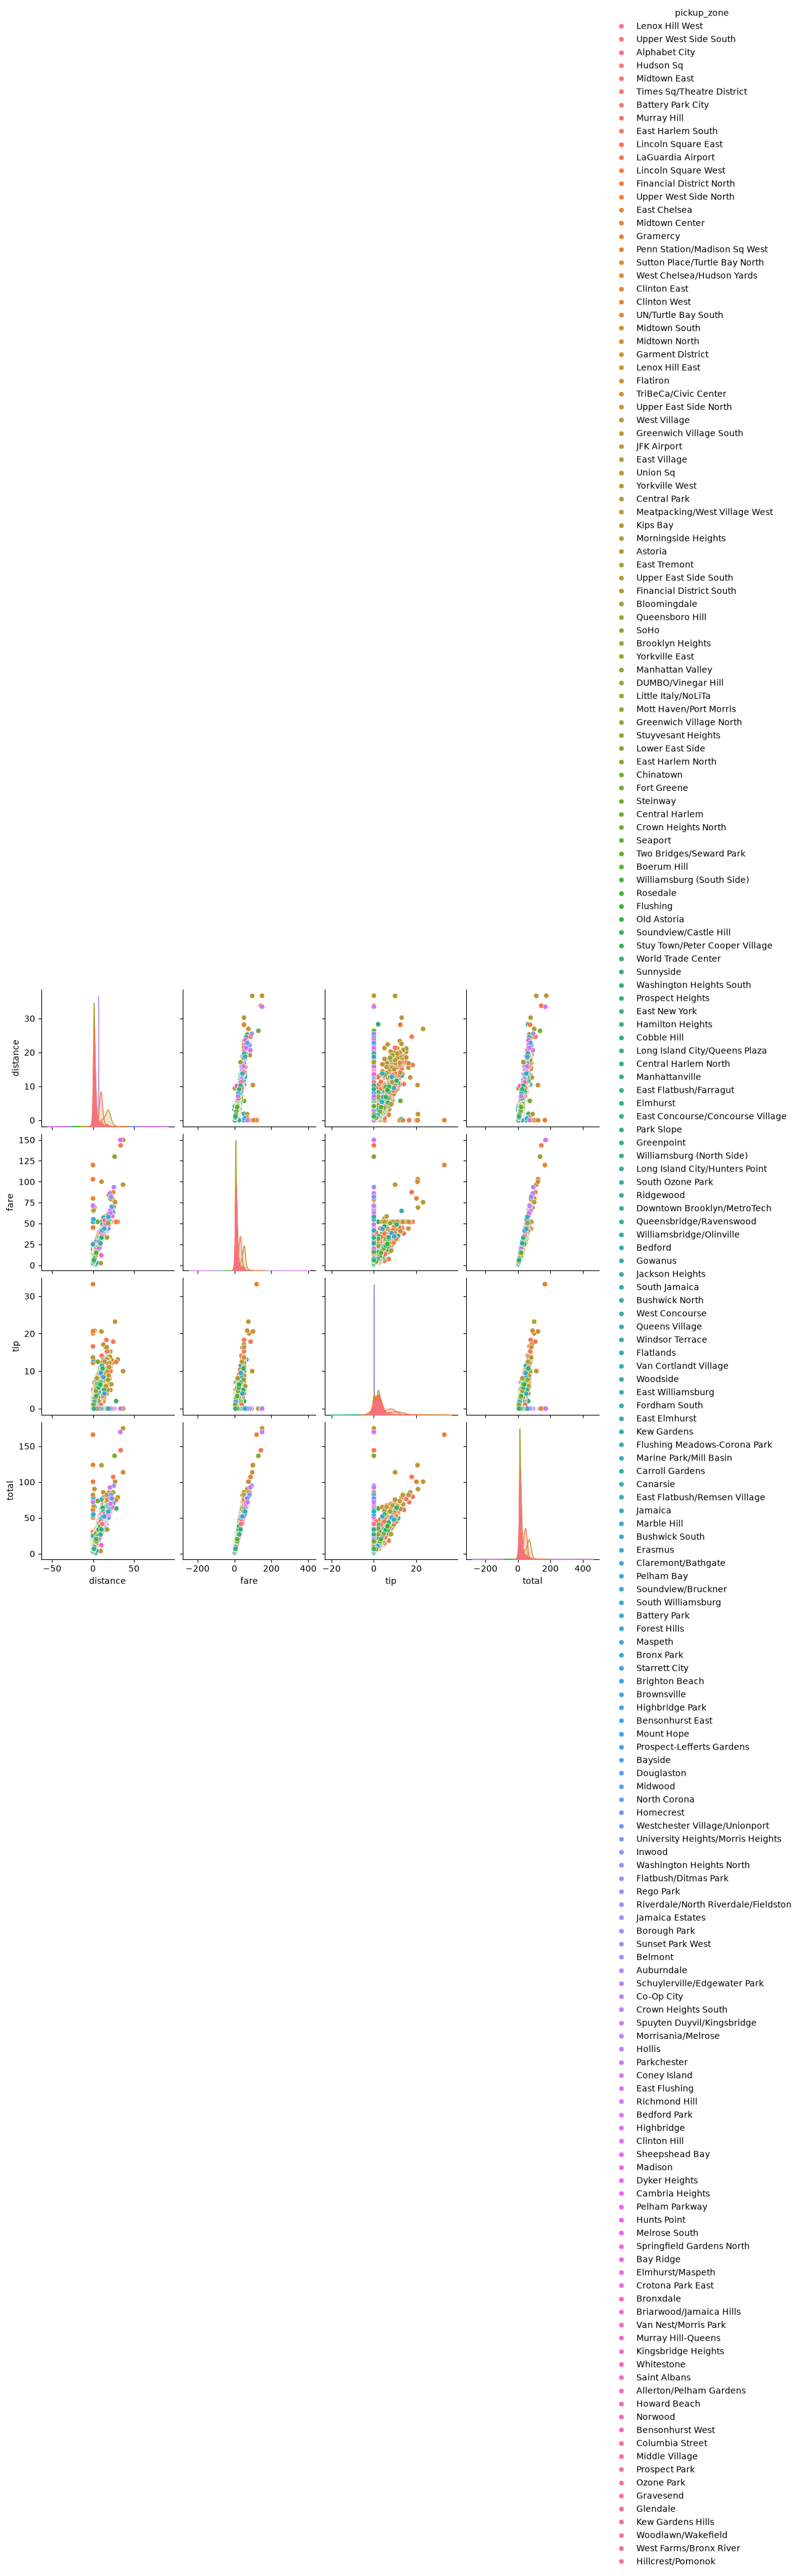

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(data, hue="pickup_zone")

plt.show()


**Violin PLot**

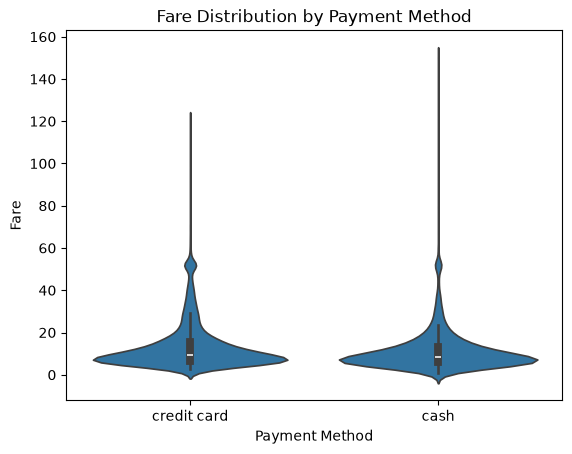

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.violinplot(data=df, x="payment", y="fare")

plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.title("Fare Distribution by Payment Method")

plt.show()
